**copied from /admin-where-is-M1/w1-extract-cm229-topo.ipynb**

In [ ]:
import sys; sys.path.insert(0, '../..')
from paths import ROOT, DATA, STEPS, PREPARES, FIGURES, OUTPUT, CODE


In [2]:
import h5py
import pickle
import scipy
import numpy as np
import seaborn as sns
# sns.set()
sns.set_style("whitegrid", {'axes.grid' : False})
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import pandas as pd
from os.path import join as pjoin
import scipy.io as sio
from scipy import stats
import scipy.signal as sp
from scipy import signal
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans

from statannot import add_stat_annotation
# from skimage import io
# from skimage.feature import hog
from joblib import Parallel, delayed
import cv2
import glob
import time
# from skimage.registration import phase_cross_correlation
from scipy.ndimage import fourier_shift
from joblib import Parallel, delayed
# from skimage.feature import hog
import sys
sys.path.insert(1, str(CODE / 'make_0_prepare' / 'common-functions'))
from harness import *
from f2_utils import *
import matplotlib.patches as patches

from IPython.display import display, clear_output, HTML, Image
from matplotlib import animation, rc

from skimage.measure import regionprops

from matplotlib import cm as mpl_cm
from matplotlib import (colors,
                        lines,
                        transforms,
                        )
from matplotlib import patches

import time_in_each_roi

In [3]:
prefix = '/mnt/staging/' # or 
step_0_root = str(STEPS / "step_0") + "/"
step_1_root = str(STEPS / "step_1") + "/"
step_2_root = str(STEPS / "step_2") + "/"
step_3_root = str(STEPS / "step_3") + "/"

fetch_path_S1 = str(PREPARES / "index-S1") + "/"
fetch_path_M2 = str(PREPARES / "index-M2") + "/"
fetch_path_M1 = str(FIGURES / "figure5") + "/"
fetch_path_extra = str(PREPARES / "index-extra") + "/"
figure_config_root = str(PREPARES / "config") + "/"
data_root = str(PREPARES / "epochs-rest-to-running") + "/"
figure3_root = str(FIGURES / "figure3") + "/"
mouse='cm125'

In [62]:
def contour_to_roi(image,contour):
    import scipy.ndimage as ndimage  
    r = mask
    r_mask = np.zeros_like(r, dtype='bool')
    r_mask[np.round(contour[:, 0]).astype('int'), np.round(contour[:, 1]).astype('int')] = 1
    r_mask = ndimage.binary_fill_holes(r_mask)
    
    r_mask = r_mask.astype('float')
    r_mask[r_mask == 0] = np.nan

    return r_mask

In [93]:
from skimage.draw import polygon
import scipy.ndimage as ndimage
def contour_to_roi(image, contour):
    r_mask = np.zeros_like(image, dtype=bool)

    # Extract x, y coordinates and close the contour if necessary
    x = np.round(contour[:, 0]).astype(int)
    y = np.round(contour[:, 1]).astype(int)

    # Ensure valid indices
    x = np.clip(x, 0, image.shape[0] - 1)
    y = np.clip(y, 0, image.shape[1] - 1)

    # Fill the polygon using skimage's `polygon` function
    rr, cc = polygon(x, y, image.shape)
    r_mask[rr, cc] = 1

    # Fill holes inside the region
    r_mask = ndimage.binary_fill_holes(r_mask)

    # Convert to float and set background to NaN
    r_mask = r_mask.astype(float)
    r_mask[r_mask == 0] = np.nan

    return r_mask


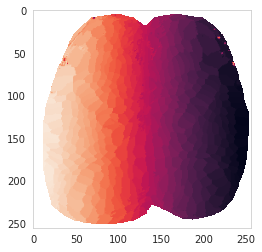

In [4]:
with h5py.File(step_0_root+mouse+'/idx_sorted_500_{}.mat'.format(mouse),'r') as f_idx:

    IDX_sorted = np.array(f_idx['IDX_sorted']).T
    IDX_sorted = IDX_sorted.astype(float)
    IDX_sorted[IDX_sorted==0]='nan'
    num_regions = int(np.nanmax(IDX_sorted.reshape((-1,1))))
    props = regionprops(IDX_sorted.astype(int))
    node_coords = [props[i].centroid for i in range(len(props))]
    node_coords = np.asarray(node_coords, dtype=np.float32)
    
    mask = IDX_sorted >0
    mask = mask.astype(float)
    mask[mask==0]='nan'
plt.imshow(IDX_sorted)

In [54]:
M2_ind = load_pickle(fetch_path_M2+'brightest_frontline_ind-'+mouse)
sensory_ind = load_pickle(fetch_path_S1+'inferred_brightest_ind_'+mouse)
# all_ind = sensory_ind.copy()
# extra_ind = load_pickle(fetch_path_extra+'extra_ind_'+mouse)
# extra_extra_ind = load_pickle(fetch_path_extra+'extra_extra_ind_'+mouse)
# all_ind.update(extra_ind)



In [7]:
M_raw={}
t1 = 340
with h5py.File(step_1_root+'{}/{}/{}_stim_1.mat'.format(mouse,'1','runB'),'r') as f_H: 
    for key in ['green','lime','red']:
        C = np.array(f_H['C'][key])
        S = np.array(f_H['S'][key])[t1:t1+1,:]
        CS = np.dot(S,C).transpose()

        temp = CS
        temp = temp.reshape((256,256,-1)).transpose((1,0,2))     

        # temp_norm = temp-np.mean(temp[:,:,bsl],axis=-1)[:,:,np.newaxis]
        M_raw[key] = temp


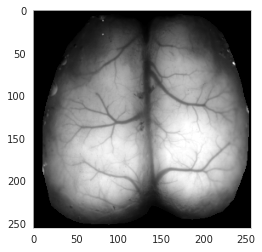

In [8]:
masked_brain = np.multiply(np.squeeze(M_raw['lime']),mask)
masked_brain=np.nan_to_num(masked_brain,0)
plt.imshow(masked_brain,cmap='gray',vmin=500,vmax=4500)

In [9]:
palatte_dict = load_pickle(figure_config_root+'palatte_dict')
# for S1 homunculus
palatte_dict['mouth']=palatte_dict['RM']
palatte_dict['nose']=palatte_dict['RN']
palatte_dict['LV'] = '#ee8c7d'
palatte_dict['tail'] = 'palegreen'

In [10]:
# (137,130) #bregma location
pixels_per_mm = 29
x_axis = np.divide(np.linspace(-135,256-135-1,256),pixels_per_mm)
y_axis = np.divide(np.linspace(256-130-1,-130,256),pixels_per_mm)
extent = [x_axis[0],x_axis[-1],y_axis[-1],y_axis[0]]


**some indices from coherence**

In [11]:
# mega_dict_coherence = load_pickle(fetch_path_M1+'mega_dict_coherence_'+'cm125')
# print(mega_dict_coherence.keys())
# M1_ind = mega_dict_coherence['mega_M1_ind_from_coherence']

In [55]:
# RE-ORDER
choice_body_part_dict = {0:'RHP',1:'RFP',2:'RW',3:'RV',
                         4:'RM_M2',5:'RFP_M2',6:'LatM'}
choice_dict = {0:316,1:400,2:sensory_ind['RW'],3:406,4:[],5:[],6:418}

In [56]:
palatte_dict['RM_M2']='#bf8fc9'
palatte_dict['RFP_M2']='#6dae96'
palatte_dict['RFP_M1']='#4b0082'
palatte_dict['LatM']=palatte_dict['ALM']
# palatte_dict['RV']='lightseagreen'

In [57]:
dict_seed_ROI_xy_mice  = load_pickle(figure_config_root+'dict_seed_ROI_xy_mice')

list_choice_M2_l_n_r = ['RFP','RM','RW','RHP','LFP','LM','LW','LHP']
seed_ROI_xy = dict_seed_ROI_xy_mice[mouse]

# jrgeco2plot_M2 = {};
node_coords_M2 = {}
for i_bdp in range(8):
    bdp = list_choice_M2_l_n_r[i_bdp]
    y_top_left = seed_ROI_xy[bdp]['y_top_left']
    y_botton_right = seed_ROI_xy[bdp]['y_botton_right']
    x_top_left =seed_ROI_xy[bdp]['x_top_left']
    x_botton_right=seed_ROI_xy[bdp]['x_botton_right']
    node_coords_M2[bdp] = np.array([(y_top_left+y_botton_right)/2,(x_top_left+x_botton_right)/2])
    # small_roi_tcs = np.nanmean(np.nanmean(
    #     MM_jrgeco[x_top_left:x_botton_right,y_top_left:y_botton_right],0),0)
    # jrgeco2plot_M2[bdp] = small_roi_tcs


In [104]:
fetch_path = str(FIGURES / "figure2") + "/"
clean_contours_S1 = load_pickle(fetch_path+'clean_contours_'+'cm229')
clean_contours_cm241 = load_pickle(fetch_path+'clean_contours_'+'cm241')
clean_contours_S1['LW']=clean_contours_cm241['LW'];
clean_contours_S1['RW']=clean_contours_cm241['RW'];

clean_contours_S1['LM'] = clean_contours_S1['mouth'] 
clean_contours_S1['RM'] = clean_contours_S1['mouth'] 


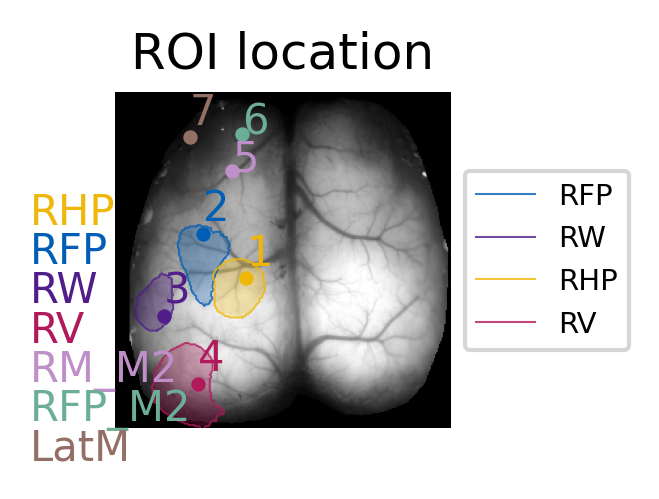

In [106]:
from matplotlib.gridspec import GridSpec
from skimage import measure
from matplotlib import ticker
import matplotlib
plt.style.use('default')

gs = GridSpec(100,100)
# with plt.style.context(spstyle.get_style('nature')):
plt.rcParams['svg.fonttype'] = 'none'
fig = plt.figure(figsize=(30,30),dpi=300)

y_offset = 20;x_offset=20;
x_width=5;

x_start = x_offset
x_stop = x_start+x_width
ax0 = fig.add_subplot(gs[y_offset:y_offset+5,x_start:x_stop])

ax0.imshow(masked_brain,cmap='gray',vmin=500,vmax=4500)

for i_bdp,bdp_ind in enumerate(choice_body_part_dict):
    y_value = 100+i_bdp*30
    
    ind = choice_dict[i_bdp]
    bdp = choice_body_part_dict[bdp_ind]
    if len(bdp.split('_'))==1:
        ax0.scatter(node_coords[ind,1],node_coords[ind,0],s=6,color=palatte_dict[bdp])
        ax0.text(node_coords[ind,1],node_coords[ind,0]-10,i_bdp+1,
             color=palatte_dict[bdp])
    else:
        if bdp.split('_')[1] == 'M2':
            ax0.scatter(node_coords_M2[bdp.split('_')[0]][0], node_coords_M2[bdp.split('_')[0]][1], s=6, c=palatte_dict[bdp], zorder=2)
            ax0.text(node_coords_M2[bdp.split('_')[0]][0],node_coords_M2[bdp.split('_')[0]][1],i_bdp+1,
                 color=palatte_dict[bdp])
        else:
            ax0.scatter(node_coords[ind,1],node_coords[ind,0],s=6,color=palatte_dict[bdp])
            ax0.text(node_coords[ind,1],node_coords[ind,0]-10,i_bdp+1,
                 color=palatte_dict[bdp])

    ax0.text(-65,y_value,
             bdp,color=palatte_dict[bdp])
    
    
# add S1 contour
bdp_w_order = [ 'RFP', 'RW','RHP','RV']

for ikey,bodypart_name in enumerate(bdp_w_order):
    bodypart_name_R =bodypart_name# 'R'+bodypart_name[1:]
    for contour in clean_contours_S1[bodypart_name_R]:
        r_mask = contour_to_roi(np.ones((256,256)),contour)
        c_black= matplotlib.colors.colorConverter.to_rgba(palatte_dict[bodypart_name_R],alpha = 0.3)
        c_black1= matplotlib.colors.colorConverter.to_rgba(palatte_dict[bodypart_name_R],alpha = 0.2)
        c_white= matplotlib.colors.colorConverter.to_rgba(palatte_dict[bodypart_name_R],alpha = 0.1)
        cmap_rb = matplotlib.colors.LinearSegmentedColormap.from_list('rb_cmap',[c_white,c_black1,c_black],5120)
        ax0.imshow(r_mask,vmin=0.1,vmax=1,cmap=cmap_rb)

        ax0.plot((contour[:,1]),(contour[:,0]),linewidth=0.5,alpha=0.8,
                 # linestyle='dashed',
                 label=bodypart_name,color=palatte_dict[bodypart_name_R])
        
        
    
    
ax0.axis('off')
# ax0.scatter(0,0,s=30,marker='+',color='white',alpha=0.8) #bregma location
ax0.legend(loc='center left',fontsize=7, bbox_to_anchor=(1, 0.5))
ax0.set_title('ROI location')
# # ax0.set_xlabel('L-R (mm)')
# # ax0.set_ylabel('P-A (mm)')

plt.savefig('fig2-ROI-locations.svg',format='svg',dpi=300)



In [97]:
behavior_colors = ['#E64B35', '#4DBBD5', '#00A087', '#3C5488',
                  '#F39B7F', '#8491B4', '#91D1C2FF','#7E6148','#B09C85', '#DC0000'
                   ]

In [98]:
col_list = ["grey"] +  ["dark magenta"] + ["emerald green"] + ["golden rod"] + ["tomato"] + ["marine blue"] +["medium blue"]
col_list_palette = sns.xkcd_palette(col_list)

# triangular plots

load data

In [114]:
load_list = ['norm_M_jrgeco', 'norm_M_rotf', 'norm_M_face_pc', 'norm_M_body_pc', 'norm_M_pupil_pc_norm', 
 'norm_M_whisk_vel_norm', 'norm_M_nose_vel_norm', 'norm_M_LFP_vel_norm', 'norm_M_RFP_vel_norm',
 'M_day_label', 'M_is_groom', 'M_ind', 'norm_M_mirrorRFP_vel_norm', 'norm_M_mirrorLFP_vel_norm', 
 'norm_M_mirrorRHP_vel_norm', 'norm_M_mirrorLHP_vel_norm']

f = scipy.io.loadmat(data_root+'final_'+mouse+'_norm.mat')

for item in load_list:
    exec("{}=np.squeeze(f['{}'])".format(item,item))
T_PRE=200;
T_POST=300;
T=T_PRE+T_POST


filename=figure3_root+'figure3_avg_spectrogram.pickle'
spectrogram_dict = load_pickle(filename)
dict_slinn = spectrogram_dict['dict_slinn']
dict_f = spectrogram_dict['dict_f']

In [100]:

load_filename = data_root+'final_'+mouse+'_MM_full.h5'
# Load and baseline-subtract in blocks of 16 rows. The original built a second
# full-size array here (np.array(...), then MM_jrgeco - np.mean(...)), so it needed two
# copies of the stack live at once: 2 x 31.7 GB = 63.5 GB for cm125, which OOM-kills a
# 48 GB machine (exit 137). This holds one 31.7 GB array plus one ~2 GB block, and
# reads stay sequential; measured on an M4 Pro it finishes in 49 s with 6.4 GB max
# resident.
# Bit-identical to the original: np.array_equal(..., equal_nan=True) is True, because
# blocking along axis 0 leaves the axis-2 reduction untouched. See
# a memory-safe chunked loader.
with h5py.File(load_filename, 'r') as hf:
    dset = hf['MM_jrgeco']
    MM_jrgeco = np.empty(dset.shape, dtype=dset.dtype)
    for i_x0 in range(0, dset.shape[0], 16):
        blk = dset[i_x0:i_x0 + 16]
        MM_jrgeco[i_x0:i_x0 + 16] = blk - np.mean(blk[:,:,T_PRE-100:T_PRE,:],2)[:,:,np.newaxis,:]
    del blk, dset

In [107]:
dict_seed_ROI_xy_mice  = load_pickle(figure_config_root+'dict_seed_ROI_xy_mice')

list_choice_M2_l_n_r = ['RFP','RM','RW','RHP','LFP','LM','LW','LHP']
seed_ROI_xy = dict_seed_ROI_xy_mice[mouse]

jrgeco2plot_M2 = {};node_coords_M2 = {}
for i_bdp in range(8):
    bdp = list_choice_M2_l_n_r[i_bdp]
    y_top_left = seed_ROI_xy[bdp]['y_top_left']
    y_botton_right = seed_ROI_xy[bdp]['y_botton_right']
    x_top_left =seed_ROI_xy[bdp]['x_top_left']
    x_botton_right=seed_ROI_xy[bdp]['x_botton_right']
    node_coords_M2[bdp] = np.array([(y_top_left+y_botton_right)/2,(x_top_left+x_botton_right)/2])
    small_roi_tcs = np.nanmean(np.nanmean(
        MM_jrgeco[x_top_left:x_botton_right,y_top_left:y_botton_right],0),0)
    jrgeco2plot_M2[bdp] = small_roi_tcs
    
H_jrgeco_new_bsl=getH_4D(MM_jrgeco,IDX_sorted)

In [102]:
jrgeco2plot ={}
for i_bdp in range(7):
    bdp = choice_body_part_dict[i_bdp]
    ind = choice_dict[i_bdp]
    if len(bdp.split('_'))==1:
        jrgeco2plot[bdp]=H_jrgeco_new_bsl[ind,:,:]
    else:
        if bdp.split('_')[1] == 'M2':
            jrgeco2plot[bdp] = jrgeco2plot_M2[bdp.split('_')[0]]
            
        else:
            jrgeco2plot[bdp] = jrgeco2plot[bdp.split('_')[0]]
            


In [112]:
figure_config_root = str(PREPARES / "config") + "/"
spectrogram_cmap = load_pickle(figure_config_root+'spectrogram_cmap')

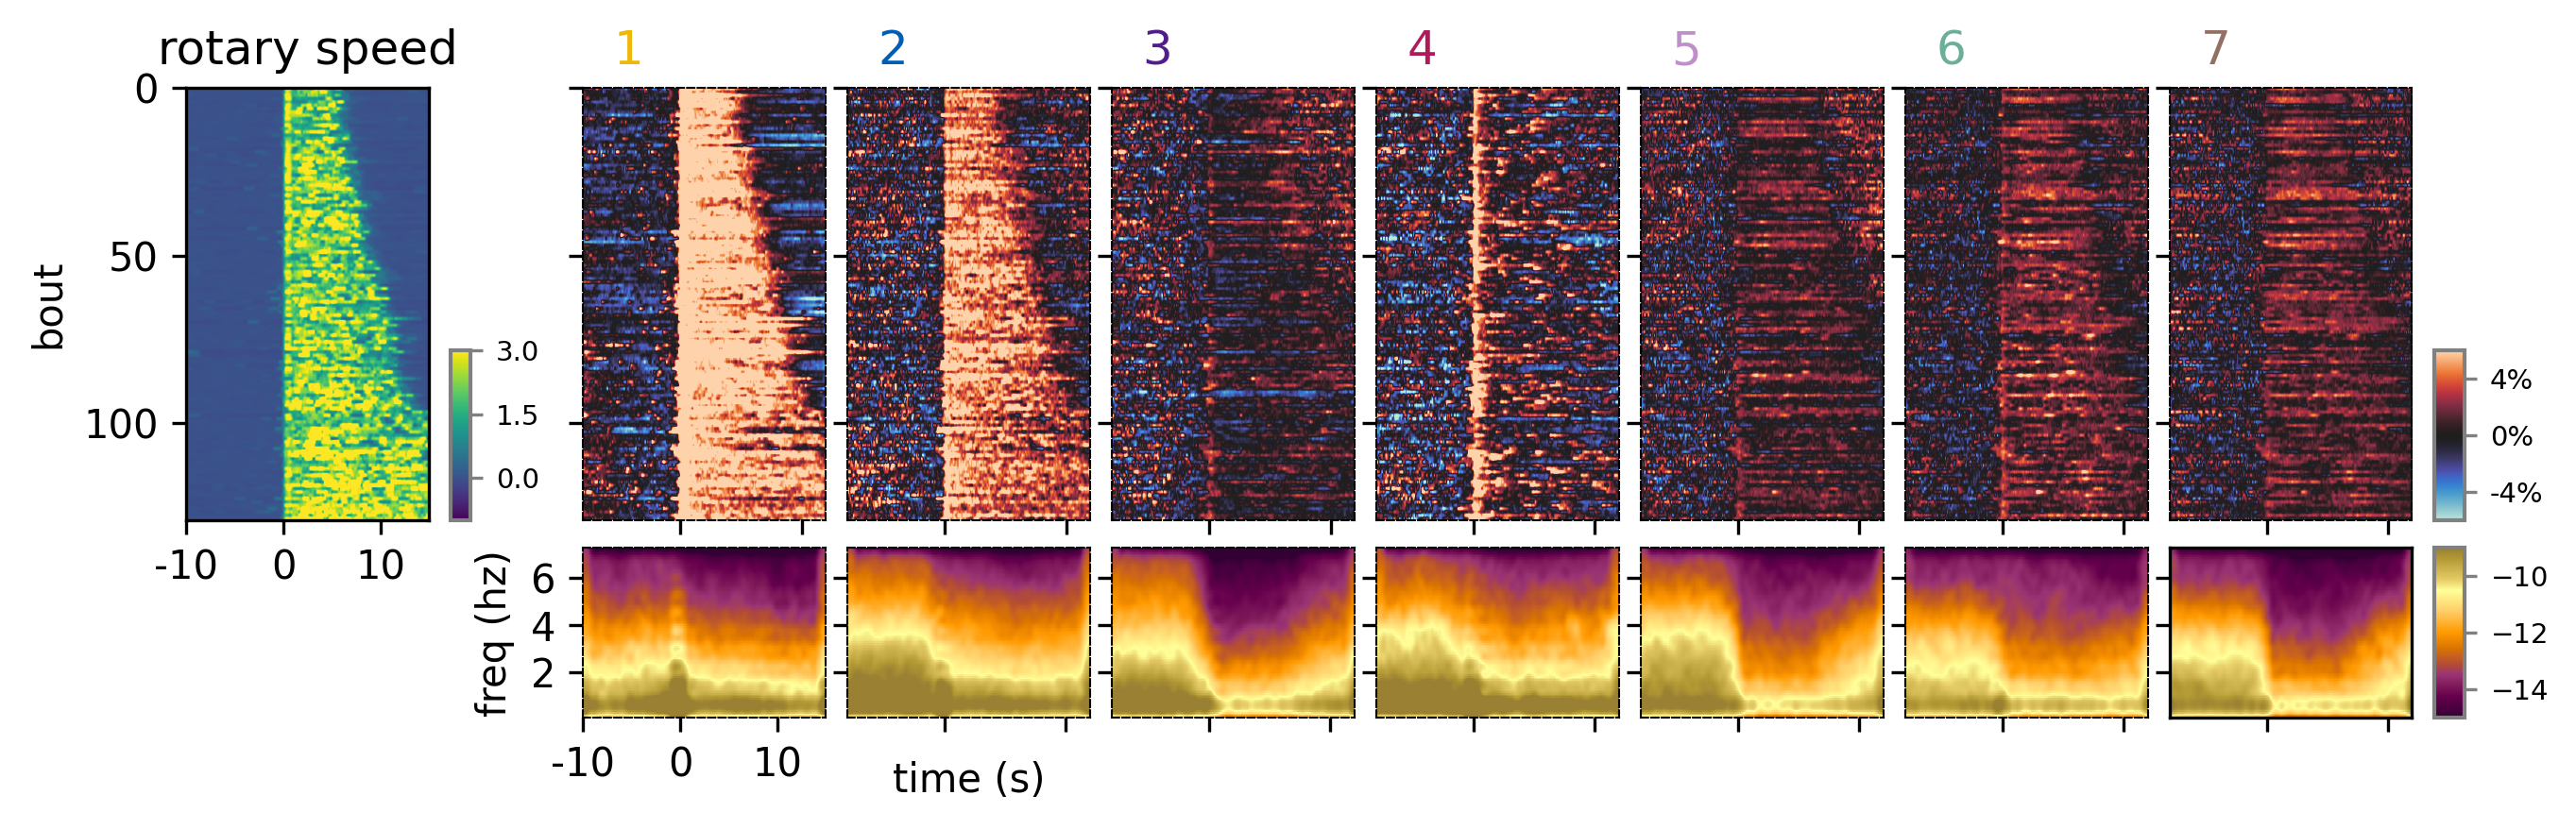

In [116]:
plt.style.use('default')
from matplotlib.ticker import FuncFormatter
fmt = lambda x, pos: '{:.0%}'.format(x)

gs = GridSpec(100,100)
# with plt.style.context(spstyle.get_style('nature')):
plt.rcParams['svg.fonttype'] = 'none'
fig = plt.figure(figsize=(30,30),dpi=300)

y_offset = 20;x_offset=20;
x_width=4;

# rotary intensity
ax000 = fig.add_subplot(gs[y_offset:y_offset+7,x_offset-2-x_width:x_offset-2])
# colorbar for rotary
ax97 = fig.add_subplot(gs[y_offset+4:y_offset+7,x_offset-2:x_offset])

x_start = x_offset 
x_stop = x_start+x_width
for i_ax in range(0,7):
    exec("ax{} = fig.add_subplot(gs[y_offset:y_offset+7,x_start:x_stop])".format(i_ax))
    x_start = x_stop 
    x_stop = x_start + x_width
    

x_start = x_offset 
x_stop = x_start+x_width
for i_ax in range(7,14):
    exec("ax{} = fig.add_subplot(gs[y_offset+7:y_offset+10,x_start:x_stop])".format(i_ax))
    x_start = x_stop 
    x_stop = x_start + x_width
    
    
ax98 = fig.add_subplot(gs[y_offset+4:y_offset+7,x_start:x_start+2]) 
ax99 = fig.add_subplot(gs[y_offset+7:y_offset+10,x_start:x_start+2])  
##########################################   
t_stop = T
x=np.linspace(-T_PRE,T_POST-1,T)
my_xticks = np.divide(x,20)
y = range(norm_M_body_pc.shape[1])
my_yticks = range(norm_M_body_pc.shape[1])

t_frame = np.linspace(-200,299,500).astype('int')
t_ax = np.divide(t_frame,20)


for i_bdp in range(7):
    bdp = choice_body_part_dict[i_bdp]
    ind = choice_dict[i_bdp]
    # data_2_plot = norm_M_jrgeco[ind,:t_stop,:]
    data_2_plot = jrgeco2plot[bdp][:t_stop,:]
    # exec("sns.heatmap(data_2_plot.transpose(),vmin=-0.05,vmax=0.05,cmap='coolwarm',ax=ax{},cbar=False)".format(i_key+3))
    exec("sbp00=ax{}.imshow(data_2_plot.transpose(),extent=[x[0],x[-1],y[0],y[-1]],aspect='auto',vmin=-0.06,vmax=0.06,cmap='icefire')".format(i_bdp))
    exec("ax{}.invert_yaxis()".format(i_bdp))
    # exec("ax{}.set_xticks([]);".format(i_bdp))
    # exec("ax{}.set_yticks([])".format(i_bdp))
    exec("ax{}.set_title(str(i_bdp+1)+'          ',color=palatte_dict[bdp])".format(i_bdp))
    # if i_bdp >0:
    exec("ax{}.set_yticklabels([])".format(i_bdp))
    exec("ax{}.set_xticklabels([])".format(i_bdp))
    
sbp000 = ax000.imshow(norm_M_rotf.transpose(),vmin=-1,vmax=3,
            extent=[x[0],x[-1],y[0],y[-1]],aspect='auto',cmap='viridis')
ax000.invert_yaxis()
ax000.set_xticks(np.array(x[::200],dtype='int'),np.array(my_xticks[::200],dtype='int'));
ax000.set_yticks(np.array(y[::50],dtype='int'),np.array(my_yticks[::50],dtype='int'))


for i_bdp in range(7):
    bdp = choice_body_part_dict[i_bdp]
    ind = choice_dict[i_bdp]
    f=dict_f[bdp];Slinn=dict_slinn[bdp]
    exec("sbp0 = ax{}.pcolormesh(x, f, np.log(np.mean(Slinn,axis=1)),rasterized=True,vmin=-15,vmax=-9,cmap=spectrogram_cmap)".format(i_bdp+7))
    # exec("ax{}.set_xticks([]);".format(i_bdp+8))
    # exec("ax{}.set_yticks([]);".format(i_bdp+8))
    exec("ax{}.set_ylim([0.05,7.3])".format(i_bdp+7))
    exec("ax{}.set_yticks([2,4,6])".format(i_bdp+7))
    if i_bdp >0:
        exec("ax{}.set_yticklabels([])".format(i_bdp+7))
        exec("ax{}.set_xticklabels([])".format(i_bdp+7))
    else:
        exec("ax{}.set_ylabel('freq (hz)')".format(i_bdp+7))
        exec("ax{}.set_xticks(np.array(x[::200],dtype='int'),np.array(my_xticks[::200],dtype='int'));".format(i_bdp+7))

        
cb = fig.colorbar(sbp000, cax=ax97,fraction=0.5,orientation='vertical');
cb.ax.tick_params(labelsize=7,length=3,color='gray')
cb.ax.yaxis.tick_right()       
cb.outline.set_edgecolor('gray')
cb.outline.set_linewidth(1)
tick_locator = ticker.MaxNLocator(nbins=3)
cb.locator = tick_locator
cb.update_ticks()
ax97.set_aspect(2.2)
ax97.set_anchor('W')

cb = fig.colorbar(sbp00, cax=ax98,fraction=0.5,orientation='vertical',format=FuncFormatter(fmt));
cb.ax.tick_params(labelsize=7,length=3,color='gray')
cb.ax.yaxis.tick_right()       
cb.outline.set_edgecolor('gray')
cb.outline.set_linewidth(1)
tick_locator = ticker.MaxNLocator(nbins=3)
cb.locator = tick_locator
cb.update_ticks()
ax98.set_aspect(47)
ax98.set_anchor('W')

cb = fig.colorbar(sbp0, cax=ax99,fraction=0.5,orientation='vertical');
cb.ax.tick_params(labelsize=7,length=3,color='gray')
cb.ax.yaxis.tick_right()       
cb.outline.set_edgecolor('gray')
cb.outline.set_linewidth(1)
tick_locator = ticker.MaxNLocator(nbins=3)
cb.locator = tick_locator
cb.update_ticks()
ax99.set_aspect(0.92)
ax99.set_anchor('W')

# for i_bout in range(95,119):
#     ax2.plot(my_xticks,norm_M_jrgeco[choice_ind['ALM'],:,i_bout]+0.08*i_bout,color=col_cubehelix[i_bout],linewidth=1)
# ax2.set_xlim([my_xticks[0],my_xticks[-1]])
# ax2.axvline(0)
# # add extra yticks to the ax3
# B = norm_M_jrgeco.shape[-1]
# ax3.set_yticks(list(ax3.get_yticks()) + [B-95,B-118])



for axis in ['top','right','left','bottom']:
    for i_ax in range(13):
        exec("ax{}.spines[axis].set_linewidth(0.5)".format(i_ax))
        exec("ax{}.spines[axis].set_linestyle('dashed') ".format(i_ax))

plt.subplots_adjust(hspace=0.7,wspace=0.5)
    
    
    

ax000.set_title('rotary speed')
ax000.set_ylabel('bout')
ax8.set_xlabel('time (s)')
plt.savefig('fig2-triangular-plot.svg',format='svg',dpi=300)



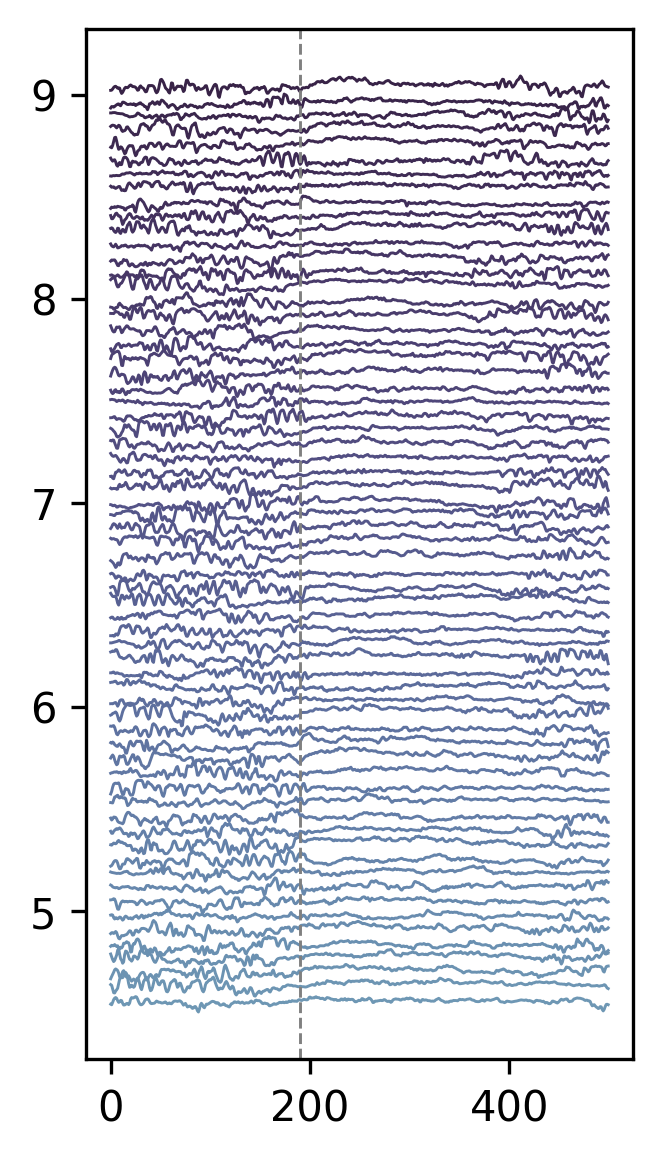

In [44]:
plt.style.use('default')
gs = GridSpec(100,100)
# with plt.style.context(spstyle.get_style('nature')):
plt.rcParams['svg.fonttype'] = 'none'
fig = plt.figure(figsize=(30,30),dpi=300)

y_offset = 20;x_offset=20;
x_width=8;

x_start = x_offset 
x_stop = x_start+x_width

ax = fig.add_subplot(gs[y_offset:y_offset+15,x_start:x_stop])
x_start = x_stop 
x_stop = x_start + x_width


    
# bdp = 'ALM'
# ind = choice_dict[i_bdp]
data_2_plot = jrgeco2plot['LatM'][:t_stop,:]
col_cubehelix = sns.cubehelix_palette(start=.5, rot=-.5, as_cmap=False,n_colors=120)
for i_count,i_bout in enumerate(range(65,130)):
    ax.plot(data_2_plot[:,i_bout]+0.07*i_bout,color=col_cubehelix[i_count+50],linewidth=0.7)
# ax.set_xlim([my_xticks[0],my_xticks[-1]])
ax.axvline(190,linewidth=0.7,color='gray',linestyle='dashed')
plt.savefig('fig2-wiggle-plot.svg',format='svg',dpi=300)